# 04 — Real chemical evolution with galevo (GalIMF)

*Lecture 2: chemical evolution*

**galevo** is the galaxy chemical-evolution module of the open-source **GalIMF** code (Yan, Jeřábková & Kroupa 2017; Yan et al. 2019):
https://github.com/Azeret/galIMF

Compared with the toy model it follows stellar lifetimes, metallicity-dependent yields of many elements, SN Ia from a delay-time distribution — and it can use a **variable, galaxy-wide IMF** computed from the IGIMF theory (`imf='igimf'`), which becomes top-heavy at high star-formation rates.

We compare three galaxies that form the **same total stellar mass** ($3\times10^9\,M_\odot$) with a flat star-formation history lasting 30 Myr, 300 Myr or 3 Gyr.

⏱ A run takes from ~30 s (30 Myr) to tens of minutes (3 Gyr). Pre-computed results are in `../data/galevo_runs/`, so you can plot first and run later.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # makes the small 'stellarpops' package importable
import numpy as np
import matplotlib.pyplot as plt
from stellarpops.style import use_slide_style
use_slide_style(dark=False, scale=0.7)       # dark=True gives the lecture-slide look

('white', '#1b1a2e')

## 1. Plot the pre-computed runs

IGIMF, 30 Myr          final mass-weighted stellar [Fe/H] = -1.48, [Mg/Fe] = +0.44
IGIMF, 300 Myr         final mass-weighted stellar [Fe/H] = -0.74, [Mg/Fe] = -0.01
Kroupa IMF, 30 Myr     final mass-weighted stellar [Fe/H] = -2.29, [Mg/Fe] = +0.44
Kroupa IMF, 300 Myr    final mass-weighted stellar [Fe/H] = -1.11, [Mg/Fe] = +0.04


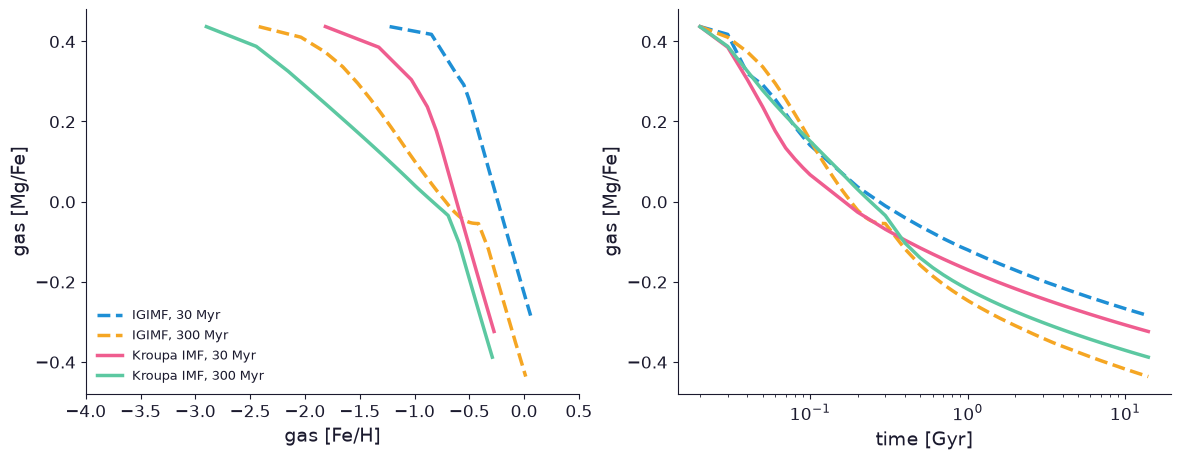

In [2]:
import glob
runs = {os.path.basename(f)[:-4]: np.load(f) for f in sorted(glob.glob('../data/galevo_runs/*.npz'))}
names = {'K_fast': 'Kroupa IMF, 30 Myr', 'K_mid': 'Kroupa IMF, 300 Myr', 'K_slow': 'Kroupa IMF, 3 Gyr',
         'I_fast': 'IGIMF, 30 Myr', 'I_mid': 'IGIMF, 300 Myr', 'I_slow': 'IGIMF, 3 Gyr'}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for k, d in runs.items():
    ls = '--' if k.startswith('I') else '-'
    t = 10 ** d['time_axis'] / 1e9
    ok = d['Fe_over_H_list'] > -5
    ax1.plot(d['Fe_over_H_list'][ok], d['Mg_over_Fe_list'][ok], ls, label=names.get(k, k))
    ax2.plot(t[ok], d['Mg_over_Fe_list'][ok], ls, label=names.get(k, k))
ax1.set_xlabel('gas [Fe/H]'); ax1.set_ylabel('gas [Mg/Fe]'); ax1.set_xlim(-4, 0.5); ax1.legend(fontsize=9)
ax2.set_xscale('log'); ax2.set_xlabel('time [Gyr]'); ax2.set_ylabel('gas [Mg/Fe]')
for k, d in runs.items():
    print(f"{names.get(k, k):22s} final mass-weighted stellar [Fe/H] = {d['stellar_Fe_over_H_list'][-1]:+.2f}, [Mg/Fe] = {d['stellar_Mg_over_Fe_list'][-1]:+.2f}")

**Questions**
1. Rank the three Kroupa-IMF galaxies by the [Mg/Fe] of their stars. Does it match the toy model?
2. Why does the gas [Mg/Fe] keep falling after star formation has stopped?
3. Compare Kroupa and IGIMF for the fast galaxy. Why does a high star-formation rate change the IMF in the IGIMF theory, and what does this do to [Mg/Fe]?

## 2. Run galevo yourself
This clones GalIMF next to the repo (once) and runs one model. Change `log_SFR` and `SFEN` (duration in units of 10 Myr; keep `log_SFR + log10(SFEN)` fixed to keep the total mass).

original_gas_mass = 10.0
log_binding_energy_initial = 58.247
time_axis: 54 [1000000, 10000000, 20000000, 30000000, 40000000, 50000000, 60000000, 70000000, 80000000, 90000000, 100000000, 200000000, 300000000, 400000000, 500000000, 600000000, 700000000, 800000000, 900000000, 1000000000, 1010000000, 1020000000, 1030000000, 1040000000, 1050000000, 1060000000, 1070000000, 1080000000, 1100000000, 1200000000, 1400000000, 1600000000, 1800000000, 2000000000, 2300000000, 2600000000, 2900000000, 3000000000, 3200000000, 3500000000, 3800000000, 4000000000, 4100000000, 4500000000, 5000000000, 6000000000, 7000000000, 8000000000, 9000000000, 10000000000, 11000000000, 12000000000, 13000000000, 14000000000]



Type Ia supernova activated. Total SNIa number per solar mass of star formed at t = 10Gyr: 0.0022081939180271363


- Simulation complete. Computation time: 0 d 0 h 0 m 13.11 s -
Generating txt output files...
simulation results saved in the file: simulation_results_from_galaxy_evol/imfKroupaSTF0.3log_SFR2.0SFEN3Z_0-6.0/(plots/)...txt
plot stellar_Fe_over_H final -2.2870227077090206


Text(0, 0.5, 'gas [Mg/Fe]')

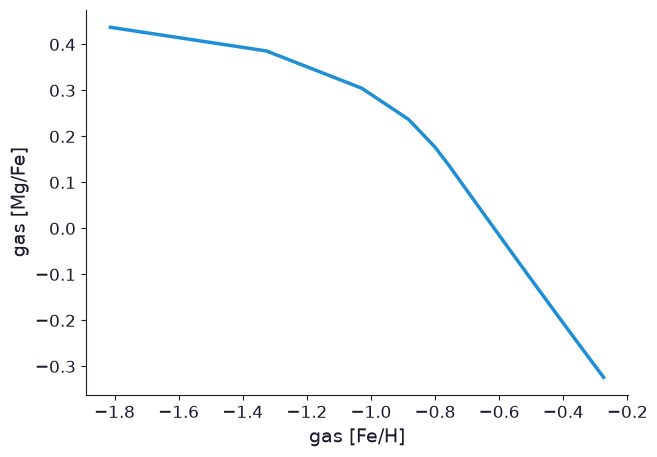

In [3]:
import subprocess
here = os.getcwd()
gal = os.path.abspath('../../galIMF')
if not os.path.isdir(gal):
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/Azeret/galIMF.git', gal], check=True)
os.chdir(gal); sys.path.insert(0, gal)
import galevo

log_SFR, SFEN, IMF = 2.0, 3, 'Kroupa'      # try IMF = 'igimf'
galevo.generate_SFH('flat', log_SFR, SFEN, 0, 10, 0)
galevo.galaxy_evol(imf=IMF, STF=0.3, SFEN=SFEN, Z_0=0.00000001886, solar_mass_component='Anders1989_mass',
                   str_yield_table='portinari98', IMF_name='Kroupa', steller_mass_upper_bound=150,
                   time_resolution_in_Myr=1, mass_boundary_observe_low=1.5, mass_boundary_observe_up=8,
                   SFH_model='provided', SNIa_ON=True, high_time_resolution=None,
                   plot_show=None, plot_save=None, outflow=None, check_igimf=False)
os.chdir(here)
plt.figure(figsize=(7, 5))
ok = np.array(galevo.Fe_over_H_list) > -5
plt.plot(np.array(galevo.Fe_over_H_list)[ok], np.array(galevo.Mg_over_Fe_list)[ok])
plt.xlabel('gas [Fe/H]'); plt.ylabel('gas [Mg/Fe]')